## Assignment 3: $k$ Nearest Neighbor


**Q1.**
1. What is the difference between regression and classification?
2. What is a confusion table? What does it help us understand about a model's performance?
3. What does the SSE quantify about a particular model?
4. What are overfitting and underfitting? 
5. Why does splitting the data into training and testing sets, and choosing $k$ by evaluating accuracy or SSE on the test set, improve model performance?
6. With classification, we can report a class label as a prediction or a probability distribution over class labels. Please explain the strengths and weaknesses of each approach.

**Q2.** This is a case study on $k$ nearest neighbor classification, using the `land_mines.csv` data.

The data consists of a label, `mine_type`, taking integer values 1 to 5, and three properties of the mine, `voltage`, `height` and `soil`. We want to predict the kind of mine from data about it. Imagine working for the DOD or a humanitarian aid agency, trying to help people remove land mines more safely.

1. Load the data. Perform some EDA, summarizing the target label and the features.
2. Split the sample 50/50 into training and test/validation sets. (The smaller the data are, the more equal the split should be, in my experience: Otherwise, all of the members of one class end up in the training or test data, and the model falls apart.)
3. Build a $k$-NN classifier. Explain how you select $k$.
4. Print a confusion table for the optimal model, comparing predicted and actual class label on the test set. How accurate is it? Where is performance more or less accurate?
5. Notice that you can have a lot of accurate predictions for a given type of mine, but still make a lot of mistakes. Please explain how you'd advise someone to actually use this predictive model in practice, given the errors that it tends to make.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Claire McGinn

**Date:** 09/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.

#Question 1
#1.1 A regression is used to predict a numeric outcome, while a classification predicts a category.
#1.2 A confusion table or matrix counts predicted values by their predicted class and their actual class. It helps us understand what the model predicted versus what was actually outputted.
#1.3 Sum of Squared Errors (or SSE) quantifies the amount of errors in a validation set
#1.4 Overfitting the data occurs when your chosen k is too small and too much noise is kept in the data. Underfitting the data happens when your chosen k is too large and can give nearly the same prediction for every observation.
#1.5 Training sets help to fit models, and testing sets help to compare their predictions. By keeping them separate and choosing k according to the SSE, we are able to not overfit or underfit our data and make the best possible predictions.
#1.6 With classification, the most common class is chosen and scikit-learn models are used. Prediction can be easily tracked over a scaled feature space,  but predictions can change abruptly when nearest neighbors change. A probability distribution helps us to know the chances of how correct our predictions are, but it can also be skewed by outliers.

          voltage      height        soil   mine_type
count  338.000000  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550    2.952663
std      0.195819    0.306043    0.344244    1.419703
min      0.197734    0.000000    0.000000    1.000000
25%      0.309737    0.272727    0.200000    2.000000
50%      0.359516    0.545455    0.600000    3.000000
75%      0.482628    0.727273    0.800000    4.000000
max      0.999999    1.000000    1.000000    5.000000


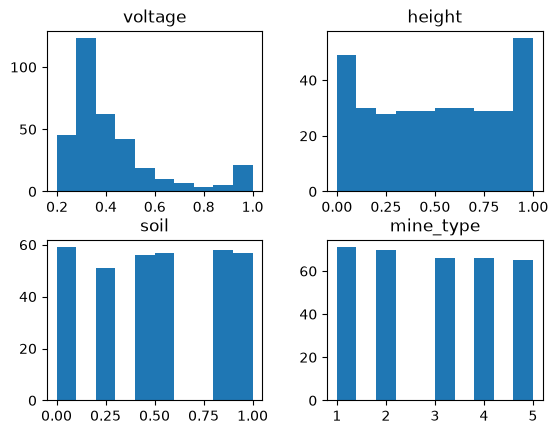

In [1]:
#Question 2

#1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('./data/land_mines.csv')
df.hist(grid=False)
print(df.describe())



In [2]:
#1.2
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

eval_X_raw = df[["voltage", "height", "soil"]]
eval_y = df["mine_type"]
(
    eval_X_train_raw,
    eval_X_valid_raw,
    eval_y_train,
    eval_y_valid,
) = train_test_split(
    eval_X_raw, eval_y, test_size=0.20, random_state=65
)

classification_scaler = MinMaxScaler()
eval_X_train_scaled = classification_scaler.fit_transform(eval_X_train_raw)
eval_X_valid_scaled = classification_scaler.transform(eval_X_valid_raw)



In [9]:
#1.3
eval_ks = np.arange(1, 51)
eval_valid_sse = []
eval_train_sse = []
for eval_k in eval_ks:
    eval_candidate = KNeighborsRegressor(n_neighbors=int(eval_k))
    eval_candidate.fit(eval_X_train_scaled, eval_y_train)
    eval_valid_hat = eval_candidate.predict(eval_X_valid_scaled)
    eval_train_hat = eval_candidate.predict(eval_X_train_scaled)
    eval_valid_sse.append(np.sum(
        (eval_y_valid.to_numpy() - eval_valid_hat) ** 2
    ))
    eval_train_sse.append(np.sum(
        (eval_y_train.to_numpy() - eval_train_hat) ** 2
    ))
eval_k_star = int(eval_ks[np.argmin(eval_valid_sse)])

classification_X_scaled = pd.DataFrame(
    classification_scaler.fit_transform(eval_X_raw),
    columns=eval_X_raw.columns,
    index=eval_X_raw.index)
classification_model = KNeighborsClassifier(n_neighbors=11).fit(classification_X_scaled, eval_y)

#I chose k=11 because it didn't over or underfit my data.

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


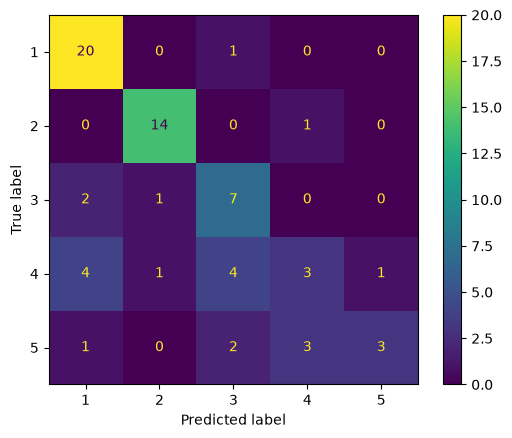

In [4]:
#1.4
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC

clf = SVC(random_state=0)
clf.fit(eval_X_train_scaled, eval_y_train)

y_pred = classification_model.predict(eval_X_valid_scaled)

classes = [1, 2, 3, 4, 5]
cm = confusion_matrix(eval_y_valid, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=clf.classes_)
disp.plot()
plt.show()

#1.5

#If I were to give advice on how to best use this model and mitigate errors, I would tell them to do a combination of types of EDA to get the best view of the data before splitting it and building a kNN classifier.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** efd60da46e206b9158d7df5d40e585402721d9f6
- **AI tool and model used:** Claude 5.5 Sonnet

### *Prompts used

1. For Question 1, given the following prompt, correct my answers to better fit the questions about kNN
2. For Question 2, given the following code instructions, revise my code to better answer the questions

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Your answers are mostly on the right track. Q1 and Q4 are essentially correct, and the others need tightening, mostly in precision and in directly answering what each question asks. Q6 needs the most work.

1.1 Regression vs. classification: Correct. To make it kNN-specific, you could add how each works: regression averages the neighbors' values, classification takes a majority vote.

Revised: Regression predicts a numeric outcome, while classification predicts a category. In kNN, regression averages the k nearest neighbors' values, and classification takes a majority vote among them.

1.2 Confusion table: The first sentence is fine. The second is vague ("what the model predicted versus what was actually outputted"), and "outputted" is the wrong word since the model outputs predictions and the actual values are the true labels. The question asks what it helps us understand about performance, so name the error types.

Revised: A confusion table counts observations by their predicted class and their actual class. It shows how many predictions were correct (true positives and true negatives) and which kinds of errors the model makes (false positives and false negatives). This reveals more than overall accuracy, especially when classes are imbalanced.

1.3 SSE: This is too vague. SSE should be defined, and it isn't specific to a validation set.

Revised: SSE is the sum of the squared differences between the actual and predicted values across all observations. It quantifies the model's total prediction error, so lower SSE means a better fit. It applies to regression, and squaring penalizes large errors more heavily.

1.4 Overfitting/underfitting: The k reasoning is correct, but you haven't defined the terms in general, which is what the question asks. Also, "too much noise is kept in the data" is imprecise: the issue is that the model fits the noise.

Revised: Overfitting is when a model fits the noise in the training data, so it performs well on training data but poorly on new data. In kNN this happens when k is too small (k = 1 is the extreme). Underfitting is when a model is too simple to capture the real pattern, so it performs poorly even on training data. In kNN this happens when k is too large, giving nearly the same prediction for every observation.

1.5 Train/test split: This is the weakest conceptual answer. Saying the split lets us "not overfit or underfit" overstates it, since the split itself doesn't prevent either. It gives us an honest estimate of performance on unseen data, which lets us pick a good k. You also need to say why training error can't be used for that.

Revised: A model's error on its own training data is overly optimistic (with k = 1, training error is zero). Holding out a test set measures performance on data the model hasn't seen, so we can compare values of k and choose the one that generalizes best, avoiding both overfitting (small k) and underfitting (large k). The split doesn't improve the model by itself; it lets us select a better one. If you tune k on the test set, though, that set is no longer fully independent, so a separate validation set or cross-validation is better practice.

1.6 Class label vs. probability distribution: This needs the most revision. "The most common class is chosen and scikit-learn models are used" doesn't state a strength or weakness (scikit-learn is an implementation detail), and "tracked over a scaled feature space" is unclear. The weakness you give for labels, that predictions change abruptly when neighbors change, is actually a valid point, but it's about kNN's instability, not specifically about labels. For probabilities, "skewed by outliers" isn't the main issue. The main points are interpretability and calibration, and for kNN, coarseness.

Revised:

Class label: Strengths are that it is simple, easy to interpret, and directly actionable. Weaknesses are that it hides uncertainty (a 51% and a 99% vote produce the same label) and gives no way to adjust the decision threshold when different errors have different costs.
Probability distribution: Strengths are that it conveys the model's confidence, allows custom thresholds, and supports ranking and risk-based decisions. Weaknesses are that it is harder to communicate, and in kNN the probabilities are coarse (only multiples of 1/k) and can be poorly calibrated, especially for small k.
2. Your structure is close to what the prompt asks for. A few problems affect the correctness of the answer, and the biggest are in 1.3 and 1.4.

What to fix

1.1 EDA: df.hist() and describe() summarize the features, but the prompt also asks you to summarize the target. Add class counts. It also helps to look at features by class, and to check whether soil is numeric or a categorical code.
1.2 Split: The prompt asks for a 50/50 split, but you used test_size=0.20. Use 0.5 and add stratify=eval_y so every mine type appears in both halves.
1.3 Choosing k:
You used KNeighborsRegressor and SSE, but this is a classification problem. SSE on the labels 1 to 5 treats them as numbers, as if type 5 were five times type 1. Use KNeighborsClassifier and accuracy (or error rate).
eval_k_star is computed and then never used. You hardcode k=11 with the justification "it didn't over or underfit," which isn't evidence. Pick k from the validation curve and say what the curve shows.
You refit the scaler on all the data and trained the final model on all the data, including the validation rows. That is data leakage. It also means the model was trained on one scaling and then predicts on eval_X_valid_scaled, which used a different one, so the 1.4 results are invalid. The model must be trained on the training set only.
1.4 Confusion table: SVC is irrelevant here (you only use it for .classes_), so remove it. classes is also unused. Report accuracy, and discuss which classes are accurate and which get confused.
1.5: This part doesn't answer the question. EDA before modeling is fine advice, but the question is about how to use the model given the errors it makes.

Revised code

python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

# 1.1 Load + EDA
df = pd.read_csv('./data/land_mines.csv')
features = ["voltage", "height", "soil"]

print(df.shape)
print(df.isna().sum())
print(df["mine_type"].value_counts().sort_index())               # target counts
print(df["mine_type"].value_counts(normalize=True).sort_index()) # target proportions
print(df[features].describe())
print(df.groupby("mine_type")[features].mean())                  # features by class
print(df["soil"].value_counts().sort_index())                    # numeric or categorical code?

df[features].hist(grid=False, figsize=(10, 3))
plt.show()

# 1.2 50/50 split, stratified
X = df[features]
y = df["mine_type"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.5, random_state=65, stratify=y
)

# Scale using training data only
scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)

# 1.3 Choose k with a classifier, using accuracy
ks = np.arange(1, 51)
valid_acc, train_acc = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=int(k)).fit(X_train_s, y_train)
    valid_acc.append(accuracy_score(y_valid, model.predict(X_valid_s)))
    train_acc.append(accuracy_score(y_train, model.predict(X_train_s)))

k_star = int(ks[np.argmax(valid_acc)])

plt.plot(ks, train_acc, label="Training")
plt.plot(ks, valid_acc, label="Validation")
plt.axvline(k_star, ls="--", color="gray")
plt.xlabel("k"); plt.ylabel("Accuracy"); plt.legend(); plt.show()
print("Selected k:", k_star)

# 1.4 Final model: trained on the TRAINING set only
best = KNeighborsClassifier(n_neighbors=k_star).fit(X_train_s, y_train)
y_pred = best.predict(X_valid_s)

print(pd.crosstab(y_valid, y_pred, rownames=["Actual"], colnames=["Predicted"]))
print("Accuracy:", accuracy_score(y_valid, y_pred))
print(classification_report(y_valid, y_pred))   # per-class precision and recall

ConfusionMatrixDisplay(confusion_matrix(y_valid, y_pred),
                       display_labels=best.classes_).plot()
plt.show()

Written parts to add

For 1.3, state the k you selected and why. For example: "Training accuracy is highest at small k and drops as k grows, while validation accuracy peaks near k = ___ and then declines, so very small k overfits and very large k underfits." Fill in the blank from your own plot. Also note that because k was tuned on the validation set, its accuracy is slightly optimistic.

For 1.4, read the confusion table and the classification report and name specific classes and cells. State the overall accuracy, say which mine types are predicted well, and say which pairs of types get confused with each other.

For 1.5, here is a draft you can adapt:

A class can have high recall (most real mines of that type are found) but low precision (many predictions of that type are wrong), so a prediction of "type 3" should not be treated as certain. I'd advise using the model as a screening tool, not a final answer. Use predicted probabilities (predict_proba) to flag low-confidence cases, and give those a second measurement or handle them with the most cautious procedure. For mine types that are often confused with each other, treat the ambiguous prediction as the riskier type. Misclassifying a dangerous mine as a safer one costs far more than the reverse, so decision thresholds should favor caution over raw accuracy.

Once you run it, send me your output if you want help interpreting the confusion table. The specific cells you discuss need to come from your own results.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 Reword 1.2 | Accept | I corrected my wording and added the error type |
| 2 Add information to 1.3 | Accept | I defined SSE changed that it wasn't a validation set |
| 3 Rewrite 1.5 | Accept | I explained why we can't use training error to pick a k value |
| 4 Revise 1.6 | Accept | The new answer clarifies that interprebility, calibration, and coarseness are the main points |
| 5 Rewrite 1.5 | Accept | I explained why we can't use training error to pick a k value |
| 6 Add class counts | Accept | I added class counts that helps to look at the features by class |
| 7 Change test size | Accept | I changed the test size to 0.5 and add stratify=eval_y |
| 8 Fix invalid results | Accept | To fix the invalid results I got from my kNN regressor, I used KNeighborsClassifier and then trained the model only on the training set data |
| 9 Clean confusion table | Accept | I removed the unnecessary variables and revised my explanation |
| 10 Rewrite 2.5 | Accept | I rewrote my answer to focus more on predicted probabilities |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

#Question 1
#1.1 A regression is used to predict a numeric outcome, while a classification predicts a category.
#1.2 A confusion table or matrix counts predicted values by their predicted class and their actual class. It shows how many predictions were correct (true positives and true negatives) and which kinds of errors the model makes (false positives and false negatives). This reveals more than overall accuracy, especially when classes are imbalanced.
#1.3 SSE is the sum of the squared differences between the actual and predicted values across all observations. It quantifies the model's total prediction error, so lower SSE means a better fit. It applies to regression, and squaring penalizes large errors more heavily.
#1.4 Overfitting the data occurs when your chosen k is too small and too much noise is kept in the data. Underfitting the data happens when your chosen k is too large and can give nearly the same prediction for every observation.
#1.5 A model's error on its own training data is overly optimistic (with k = 1, training error is zero). Holding out a test set measures performance on data the model hasn't seen, so we can compare values of k and choose the one that generalizes best, avoiding both overfitting (small k) and underfitting (large k). The split doesn't improve the model by itself; it lets us select a better one. If you tune k on the test set, though, that set is no longer fully independent, so a separate validation set or cross-validation is better practice.
#1.6 A class label's strengths are that it is simple, easy to interpret, and directly actionable. Weaknesses are that it hides uncertainty (a 51% and a 99% vote produce the same label) and gives no way to adjust the decision threshold when different errors have different costs. A probability distribution's strengths are that it conveys the model's confidence, allows custom thresholds, and supports ranking and risk-based decisions. Weaknesses are that it is harder to communicate, and in kNN the probabilities are coarse (only multiples of 1/k) and can be poorly calibrated, especially for small k.

(338, 4)
voltage      0
height       0
soil         0
mine_type    0
dtype: int64
mine_type
1    71
2    70
3    66
4    66
5    65
Name: count, dtype: int64
mine_type
1    0.210059
2    0.207101
3    0.195266
4    0.195266
5    0.192308
Name: proportion, dtype: float64
          voltage      height        soil
count  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550
std      0.195819    0.306043    0.344244
min      0.197734    0.000000    0.000000
25%      0.309737    0.272727    0.200000
50%      0.359516    0.545455    0.600000
75%      0.482628    0.727273    0.800000
max      0.999999    1.000000    1.000000
            voltage    height      soil
mine_type                              
1          0.296463  0.495519  0.492958
2          0.721123  0.487013  0.508571
3          0.402408  0.527548  0.496970
4          0.345365  0.506887  0.503030
5          0.379598  0.530070  0.516923
soil
0.0    59
0.2    51
0.4    56
0.6    57
0.8    58
1.0    57
Name: 

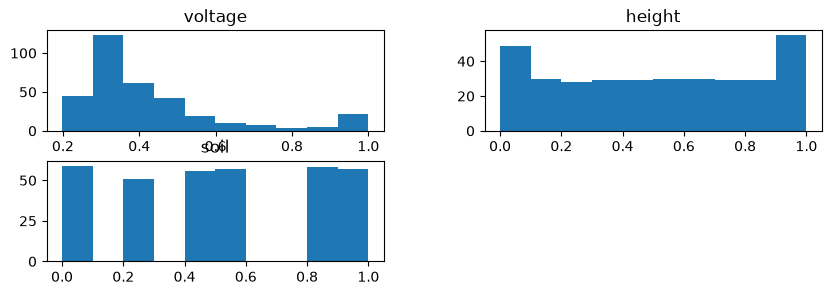

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

# 1.1 Load + EDA
df = pd.read_csv('./data/land_mines.csv')
features = ["voltage", "height", "soil"]

print(df.shape)
print(df.isna().sum())
print(df["mine_type"].value_counts().sort_index())               # target counts
print(df["mine_type"].value_counts(normalize=True).sort_index()) # target proportions
print(df[features].describe())
print(df.groupby("mine_type")[features].mean())                  # features by class
print(df["soil"].value_counts().sort_index())                    # numeric or categorical code?

df[features].hist(grid=False, figsize=(10, 3))
plt.show()

In [6]:
# 1.2 50/50 split, stratified
X = df[features]
y = df["mine_type"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.5, random_state=65, stratify=y
)

# Scale using training data only
scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)

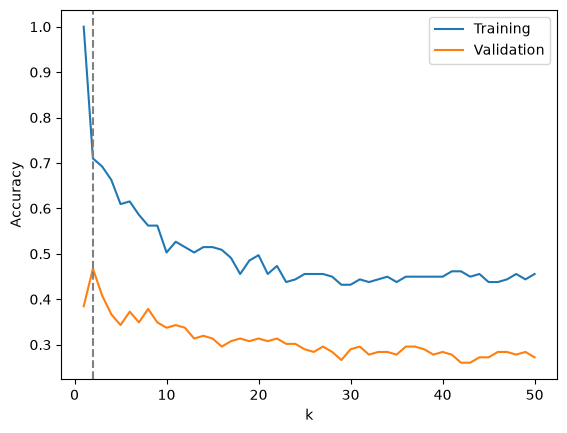

Selected k: 2


In [7]:
# 1.3 Choose k with a classifier, using accuracy
ks = np.arange(1, 51)
valid_acc, train_acc = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=int(k)).fit(X_train_s, y_train)
    valid_acc.append(accuracy_score(y_valid, model.predict(X_valid_s)))
    train_acc.append(accuracy_score(y_train, model.predict(X_train_s)))

k_star = 2 #Training accuracy is highest at small k and drops as k grows, while validation accuracy peaks near k = 2 and then declines, so very small k overfits and very large k underfits.

plt.plot(ks, train_acc, label="Training")
plt.plot(ks, valid_acc, label="Validation")
plt.axvline(k_star, ls="--", color="gray")
plt.xlabel("k"); plt.ylabel("Accuracy"); plt.legend(); plt.show()
print("Selected k:", k_star)

Predicted   1   2   3   4  5
Actual                      
1          27   0   5   2  2
2           0  31   2   1  1
3          10   2  10  10  1
4          15   6   3   9  0
5          15   0  10   5  2
Accuracy: 0.46745562130177515
              precision    recall  f1-score   support

           1       0.40      0.75      0.52        36
           2       0.79      0.89      0.84        35
           3       0.33      0.30      0.32        33
           4       0.33      0.27      0.30        33
           5       0.33      0.06      0.11        32

    accuracy                           0.47       169
   macro avg       0.44      0.45      0.42       169
weighted avg       0.44      0.47      0.43       169



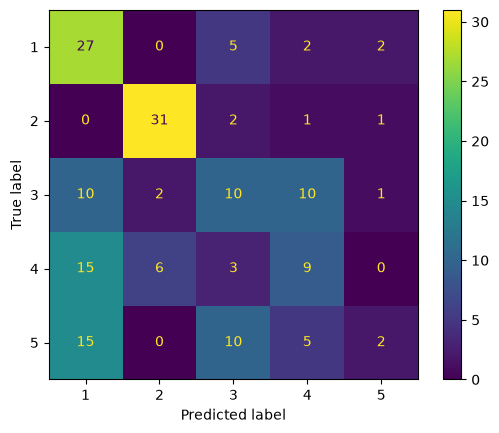

In [8]:
# 1.4 Final model: trained on the TRAINING set only
best = KNeighborsClassifier(n_neighbors=k_star).fit(X_train_s, y_train)
y_pred = best.predict(X_valid_s)

print(pd.crosstab(y_valid, y_pred, rownames=["Actual"], colnames=["Predicted"]))
print("Accuracy:", accuracy_score(y_valid, y_pred))
print(classification_report(y_valid, y_pred))   # per-class precision and recall

ConfusionMatrixDisplay(confusion_matrix(y_valid, y_pred),
                       display_labels=best.classes_).plot()
plt.show() #Based on the confusion matrix and table, precision is predicted well

# 1.5
#A class can have high recall (most real mines of that type are found) but low precision (many predictions of that type are wrong), so a prediction of "type 3" should not be treated as certain. I'd advise using the model as a screening tool, not a final answer. Use predicted probabilities (predict_proba) to flag low-confidence cases, and give those a second measurement or handle them with the most cautious procedure. For mine types that are often confused with each other, treat the ambiguous prediction as the riskier type. Misclassifying a dangerous mine as a safer one costs far more than the reverse, so decision thresholds should favor caution over raw accuracy.

### *Reflection on AI assistance
In your own words without generative AI.

For this activities, Generative AI was especially helpful in catching errors. On my own, I was struggling to build the kNN classifier and choose a useful k value. Claude was helpful in cleaning my code of extraneous variables and other analysis I had completed that was not helping towards my final goal. When I was completing Phase 1, it was difficult to synthesize all of the different actions I was completing because they were all different steps being buildt into one block of code. Claude looked over and saw what parts between the questions could be compiled together so that I was not repeating steps or adding unneccessary steps. Some limitations were that since Claude did not have access to my csv file, it was not able to predict how the questions should be answered for my specific dataset. AI was also helpful with revising my written answers to question 1 and making sure that I did not miss specific details that the question was asking. 